# 2-10 뉴스 관심도·감성 × 주가 — 뉴스가 몰린 날, 톤이 바뀐 날 주가는?

**질문 예시:** "삼성전자·SK하이닉스·리노공업 최근 석 달 뉴스량이랑 감성 비교해줘", "뉴스가 갑자기 터진 날 주가는 어땠어?", "뉴스 톤이 좋아지면 다음 날 주가도 오르나?"

CHECK 원본(`2_공시뉴스/06_뉴스커버리지감성`)을 **확장**한 시나리오입니다. CHECK 뉴스에는 종목 태그가 없어 키워드로 찾고 감성을 따로 계산해야 했지만,
DeepSearch 뉴스에는 **종목 태그(`securities`)와 긍정·중립·부정 분류**가 붙어 있어 종목별 일자 집계를 함수 하나로 받습니다.

| 단계 | DeepSearch 함수 |
|---|---|
| 종목 뉴스 일별 건수·긍부정 건수·감성점수 | `GetSentimentScore("securities.name:종목", interval="1d", …)` — 종목당 1회 |
| 주가·거래대금 | `GetStockPrices([종목들], …)` — 1회 |

`GetSentimentScore`의 `sentiment` = (긍정 − 부정) ÷ (긍정 + 중립 + 부정). 긍부정 분류가 붙은 기사만 셉니다(`total_count`는 분류 없는 기사까지 포함한 전체 건수).

**종목 태그 vs 키워드:** `securities.name:종목` 태그는 그 종목이 **제목에 나오는 주제 기사**에 붙습니다(건수가 제목 검색과 거의 같음, 2026-11-25 확인).
그냥 `종목명`으로 찾으면 시황 기사 속 **단순 언급**까지 잡혀 몇 배~수십 배 많아집니다. 감성은 태그 기준(주제 기사)으로 보고, 두 건수를 나란히 둡니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/2_disclosure_news/10_news_sentiment_price.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
START = "2026-09-01"
STOCKS = ["삼성전자", "SK하이닉스", "리노공업", "카카오게임즈", "에코프로비엠"]

## 1. 데이터 받기

In [4]:
u = universe()
name2sym = dict(zip(u["name"], u["symbol"]))

sent = {}
for n in STOCKS:
    df = ds_df(f'GetSentimentScore("securities.name:{n}", interval="1d", date_from={START}, date_to={ASOF})')
    sent[n] = df.set_index("date")[["total_count", "no_positives", "no_neutral", "no_negatives", "sentiment"]].astype(float)

# 키워드(단순 언급 포함) 기사 수는 기간 합계만 받는다
mention = {n: ds_df(f'GetSentimentScore("{n}", interval="1M", date_from={START}, date_to={ASOF})')["total_count"].sum()
           for n in STOCKS}

px = stock_prices([name2sym[n] for n in STOCKS], START, ASOF, columns=["close", "value", "change_rate"])
px["name"] = px["symbol"].map({v: k for k, v in name2sym.items()})
print(PRICE_NOTICE)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


주말·휴일 뉴스는 **다음 거래일**로 합칩니다(월요일 주가는 주말 뉴스를 반영하므로).

In [5]:
def to_trading_days(s_df, days):
    pos = days.searchsorted(s_df.index)
    ok = pos < len(days)
    g = s_df[ok].groupby(days[pos[ok]]).sum(min_count=1)
    g["sentiment"] = (g["no_positives"] - g["no_negatives"]) / (g["no_positives"] + g["no_neutral"] + g["no_negatives"])
    return g

panel = []
for n in STOCKS:
    p = px[px["name"] == n].set_index("date").sort_index()
    g = to_trading_days(sent[n], p.index)
    panel.append(p[["close", "value", "change_rate"]].join(g, how="left").assign(name=n))
panel = pd.concat(panel)
panel["ret"] = panel["change_rate"] * 100
panel["next_ret"] = panel.groupby("name")["ret"].shift(-1)

## 2. 커버리지 — 얼마나 많이, 어떤 톤으로
**긍정·부정 비율**은 분류가 붙은 기사 중 비율입니다. **뉴스량·거래대금 상관**은 거래일별 기사 수와 거래대금의 상관계수로, CHECK 원본이 말한 "뉴스량 = 관심도 프록시"를 확인합니다.

In [6]:
cov = panel.groupby("name").apply(lambda g: pd.Series({
    "주제 기사(태그)": g["total_count"].sum(),
    "거래일 평균": g["total_count"].mean(),
    "최다일 기사": g["total_count"].max(),
    "긍정 비율": g["no_positives"].sum() / g[["no_positives", "no_neutral", "no_negatives"]].sum().sum(),
    "부정 비율": g["no_negatives"].sum() / g[["no_positives", "no_neutral", "no_negatives"]].sum().sum(),
    "평균 감성점수": g["sentiment"].mean(),
    "뉴스량·거래대금 상관": g["total_count"].corr(g["value"]),
    "기간 수익률(%)": (g["close"].iloc[-1] / g["close"].iloc[0] - 1) * 100,
}), include_groups=False).loc[STOCKS]
cov.insert(1, "언급 기사(키워드)", pd.Series(mention).astype(float))
cov.round(3)

,주제 기사(태그),언급 기사(키워드),거래일 평균,최다일 기사,긍정 비율,부정 비율,평균 감성점수,뉴스량·거래대금 상관,기간 수익률(%)
name,,,,,,,,,
삼성전자,9234.0,31559.0,162.000,514.0,0.334,0.110,0.206,0.382,-27.433
SK하이닉스,4039.0,23230.0,70.860,530.0,0.363,0.137,0.178,0.062,-31.601
리노공업,25.0,1433.0,0.439,7.0,0.583,0.333,-0.147,0.158,-25.954
카카오게임즈,137.0,256.0,2.404,16.0,0.607,0.224,0.438,-0.055,26.012
에코프로비엠,90.0,2178.0,1.579,26.0,0.195,0.364,-0.174,0.349,-23.924


## 3. 뉴스 폭증일 — 그날과 다음 날 주가
폭증일 = 그 종목의 거래일 평균 기사 수의 **3배 이상이면서 평균 + 2표준편차 이상**인 날.

In [7]:
def bursts(g):
    m, s = g["total_count"].mean(), g["total_count"].std()
    b = g[(g["total_count"] >= 3 * m) & (g["total_count"] >= m + 2 * s)]
    return b.assign(평소=m)

bt = pd.concat([bursts(g) for _, g in panel.groupby("name")])
bt = bt.reset_index()[["name", "date", "평소", "total_count", "sentiment", "ret", "next_ret"]]
bt.columns = ["종목", "날짜", "평소(건/일)", "그날 기사", "그날 감성", "그날 수익률(%)", "다음날 수익률(%)"]
print(f"폭증일 {len(bt)}일 | 그날 |수익률| 평균 {bt['그날 수익률(%)'].abs().mean():.2f}% vs 전체 평균 {panel['ret'].abs().mean():.2f}%")
bt.round(2).sort_values("날짜")

폭증일 13일 | 그날 |수익률| 평균 4.35% vs 전체 평균 3.72%


,종목,날짜,평소(건/일),그날 기사,그날 감성,그날 수익률(%),다음날 수익률(%)
8,카카오게임즈,2026-09-15,2.40,13.0,-1.00,2.28,-3.74
9,카카오게임즈,2026-09-16,2.40,10.0,NaN,-3.74,0.95
10,카카오게임즈,2026-09-17,2.40,13.0,-0.44,0.95,-4.58
1,리노공업,2026-09-22,0.44,4.0,-0.75,7.45,-0.93
11,카카오게임즈,2026-09-22,2.40,11.0,-0.27,-0.22,1.46
2,리노공업,2026-10-06,0.44,7.0,0.57,3.08,-1.96
4,삼성전자,2026-10-08,162.00,514.0,0.54,-2.42,-4.39
6,에코프로비엠,2026-10-19,1.58,16.0,-0.06,8.33,-9.15
0,SK하이닉스,2026-10-28,70.86,530.0,0.72,10.89,2.62
5,삼성전자,2026-10-29,162.00,508.0,0.49,-4.13,-3.02


폭증일의 **절대 수익률**이 평소보다 크면, 뉴스량이 "큰 움직임이 있던 날"을 잘 잡는다는 뜻입니다(방향은 따로 봐야 합니다).

## 4. 감성과 수익률 — 같은 날 vs 다음 날
같은 날 상관은 "주가가 오르면 좋은 기사가 나온다"(반응)도 섞여 있습니다. **다음 날 수익률**과의 상관이 예측력에 가깝습니다.
하루 주제 기사가 3건 미만인 날은 감성이 흔들려서 빼고, 남은 거래일이 20일 미만인 종목은 `표본 부족`으로 둡니다.

In [8]:
valid = panel[panel["total_count"] >= 3]
valid = valid[valid.groupby("name")["ret"].transform("size") >= 20]
print("표본 부족(제외):", ", ".join(sorted(set(STOCKS) - set(valid["name"]))) or "없음")
corr = valid.groupby("name").apply(lambda g: pd.Series({
    "표본(거래일)": len(g),
    "감성·당일수익률 상관": g["sentiment"].corr(g["ret"]),
    "감성·다음날수익률 상관": g["sentiment"].corr(g["next_ret"]),
    "감성 상위 1/3일 다음날 평균(%)": g.loc[g["sentiment"] >= g["sentiment"].quantile(2 / 3), "next_ret"].mean(),
    "감성 하위 1/3일 다음날 평균(%)": g.loc[g["sentiment"] <= g["sentiment"].quantile(1 / 3), "next_ret"].mean(),
}), include_groups=False)
corr.round(3)

표본 부족(제외): 리노공업, 에코프로비엠, 카카오게임즈


,표본(거래일),감성·당일수익률 상관,감성·다음날수익률 상관,감성 상위 1/3일 다음날 평균(%),감성 하위 1/3일 다음날 평균(%)
name,,,,,
SK하이닉스,57.0,0.401,-0.123,-1.592,1.114
삼성전자,57.0,0.026,-0.156,-0.873,0.037


## 5. 한 종목 자세히 보기

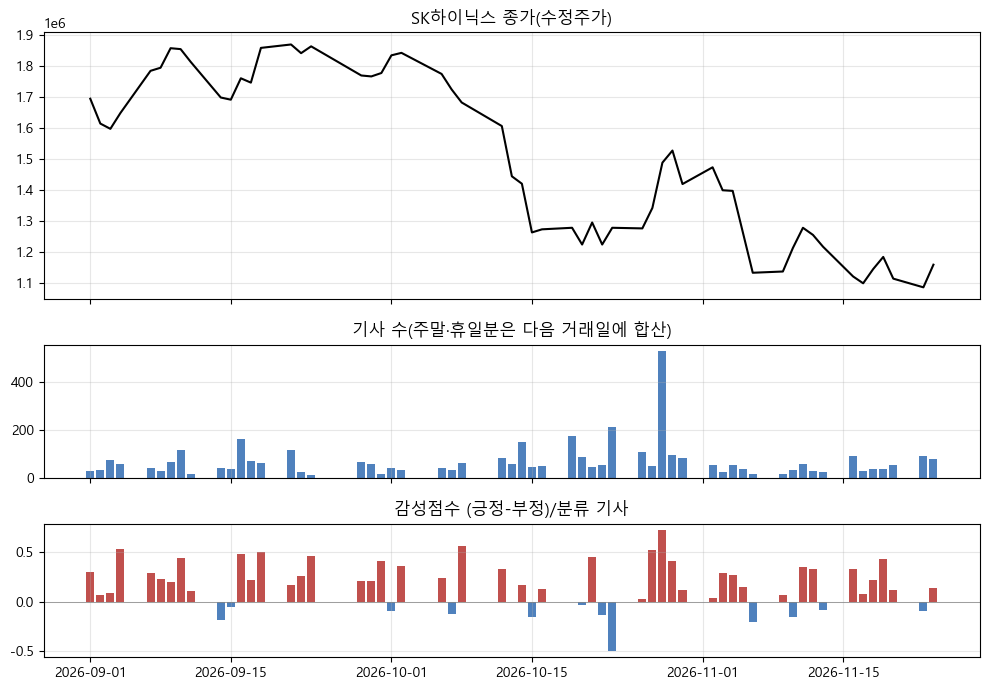

In [9]:
PICK = "SK하이닉스"
g = panel[panel["name"] == PICK]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
axes[0].plot(g.index, g["close"], color="k"); axes[0].set_title(f"{PICK} 종가(수정주가)")
axes[1].bar(g.index, g["total_count"], color="#4f81bd"); axes[1].set_title("기사 수(주말·휴일분은 다음 거래일에 합산)")
axes[2].bar(g.index, g["sentiment"], color=["#c0504d" if v >= 0 else "#4f81bd" for v in g["sentiment"].fillna(0)])
axes[2].axhline(0, color="gray", lw=.5); axes[2].set_title("감성점수 (긍정-부정)/분류 기사")
for a in axes:
    a.grid(alpha=.3)
plt.tight_layout()

## 결과 읽는 법과 한계
- **뉴스량은 관심도**입니다. 거래대금과의 상관이 높게 나오면 "뉴스가 많은 날 = 거래가 몰린 날"이라는 뜻이고, 폭증일은 큰 움직임과 겹칩니다.
- **감성은 대부분 당일 반응**입니다. 같은 날 상관이 다음 날 상관보다 크면, 기사가 주가를 따라 쓰였다고 보는 편이 맞습니다. 몇 달·몇 종목 표본으로 예측력을 단정하지 마세요.
- 긍부정은 DeepSearch 모델 분류이고, 최근 기사의 절반가량은 분류가 비어 있습니다(`total_count`와 긍정+중립+부정 합의 차이).
- 종목 태그는 기사 본문에서 자동 추출됩니다. 동명 단어(예: "오리온")가 많은 종목은 태그가 섞일 수 있어 제목·본문을 표본으로 확인하세요.